# 01 — Lakes and labels

**Goal (SPECS §4, PRD FR-1/FR-2):** build the two label tables everything else depends on.

| Output | What it is |
| --- | --- |
| `lakes.csv` | one row per glacial lake in the Hunza, Shimshal and Shigar basins (SPECS §3 schema) |
| `events.csv` | one row per GLOF event matched to a lake (SPECS §3 schema) |
| `events_unmatched.csv` | every database record that did **not** become a label, with the reason |
| `lakes_excluded.csv` | every water body that was **not** kept as a lake, with the reason |
| `lakes_polygons.geojson`, `basins.geojson` | geometries for notebook 02 and the map |
| `fig_01_basins_lakes.png`, `run_info.json` | map figure and a record of versions, parameters and counts |

**Steps:** 1 basins from HydroBASINS → 2 glacier outlines (RGI v7) → 3 lakes from JRC Global Surface Water →
4 shape filter, exclusions and Tier 2 lakes → 5 lake IDs → 6 events from the GLOF database → 7 Gate 1 checks → 8 save → 9 map.


## 0. Setup
Clones the project repository so the notebook uses the **same tested code** as the repo (`src/karaglof/`),
instead of copying logic into cells. `odfpy` reads the GLOF database spreadsheet (`.ods`).

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/inamjadoon/KaraGlof.git"
REPO_DIR = "/content/KaraGlof"
if os.path.isdir(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "odfpy==1.4.1"], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

92bf94d feat(labels): add news-reported outbursts after the database coverage



In [2]:
import json
import math
import time
import urllib.request
from datetime import UTC, datetime
from pathlib import Path

import ee
import geemap
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive

from karaglof import basins as kb
from karaglof import labels as kl
from karaglof.outlines import drained_lake

ee.Authenticate()
ee.Initialize(project="glof-497313")

drive.mount("/content/drive")
OUT = Path("/content/drive/MyDrive/KaraGlof/01_lakes")
OUT.mkdir(parents=True, exist_ok=True)
EXPORT_FOLDER = "KaraGlof_exports"   # used only if Earth Engine needs a batch export
print("outputs ->", OUT)

Mounted at /content/drive
outputs -> /content/drive/MyDrive/KaraGlof/01_lakes


## Parameters
Every choice that shapes the tables is here, in one place, so it can be reported and defended.

**Anchor points.** Basins are found from points that are surely inside or surely outside each basin
(see step 1). All anchors except Sost come straight from GLOF-database coordinates.

In [3]:
# (lon, lat)
ANCHORS = {
    "shisper":   (74.562535, 36.360999),  # Shisper (Shisphare) glacier, Hunza  — GLOF database
    "passu":     (74.879298, 36.457205),  # Passu glacier lake, Hunza           — GLOF database
    "khurdopin": (75.478606, 36.342335),  # Khurdopin glacier, Shimshal         — GLOF database
    "biafo":     (75.910000, 35.690000),  # Biafo glacier, Braldu -> Shigar     — GLOF database
    "chihnji":   (74.004089, 36.783588),  # Karambar -> Ishkoman -> Gilgit river (NOT Hunza)
    "gargoh":    (74.665676, 35.997077),  # Bagrot valley -> Gilgit river      (NOT Hunza)
    "lokpar":    (76.270137, 35.495623),  # Hushe -> Shyok                     (NOT Shigar)
    "sost":      (74.820000, 36.690000),  # Sost, Hunza main stem above Shimshal (NOT Shimshal)
}
# basin: (start anchor, anchors that must stay outside)
BASIN_RULES = {
    "shimshal":  ("khurdopin", ["sost", "passu"]),
    "hunza_all": ("shisper",   ["chihnji", "gargoh"]),   # Hunza including Shimshal
    "shigar":    ("biafo",     ["lokpar"]),
}
# Rough published catchment sizes, used only as a sanity check (warn, not fail).
EXPECTED_KM2 = {"hunza_all": 13_900, "shigar": 6_900}
BBOX = [73.5, 35.0, 77.2, 37.3]          # lon_min, lat_min, lon_max, lat_max: must contain all three basins

MIN_LAKE_KM2 = 0.01                      # PRD §4: lakes smaller than 0.01 km² are dropped
MIN_PIXELS = 12                          # 12 × 30 m × 30 m = 0.0108 km² ≥ MIN_LAKE_KM2
GLACIER_MAX_DIST_M = 10_000              # a "glacial lake" lies within 10 km of a glacier (common inventory rule)
MAX_LAKE_KM2 = 20                        # larger water bodies here are rivers or Attabad, not glacial lakes
MAX_COMPACTNESS = 25                     # perimeter² / (4π·area): 1 = circle; river reaches are far higher
SUPRAGLACIAL_SHARE = 0.5                 # >= 50% of a pond on a glacier outline = supraglacial pond, not a lake to rank
RIVER_UPA_KM2 = 100                      # water near a channel draining >= 100 km² is river, not a lake (MERIT Hydro)
RIVER_NEAR_M = 150                       # "near" = within 150 m (river lines and GSW pixels are not perfectly aligned)
EXCLUDE_POINTS = {"Attabad": (74.8667, 36.3333)}   # PRD §4: landslide-dammed lake, never a GLOF lake
EXCLUDE_RADIUS_M = 1_500

TIER2 = {"Shisper": "shisper", "Khurdopin": "khurdopin", "Passu": "passu"}   # name -> anchor
TIER2_SEARCH_M = 3_000
TIER2_OVERRIDE = {}                      # e.g. {"Passu": 123}: candidate cand_id, ONLY after checking the map
EVENT_MATCH_RADIUS_M = 3_000             # database points often sit on the glacier/dam, not in the lake
# Step 3b: Tier 2 outlines from Sentinel-2 "lake that drained" (Sentinel-2 only from 2017: project rule)
S2_FROM = "2017-01-01"
S2_WINDOW_DAYS = 30                      # look this many days before and after each dated drainage
S2_MAX_CLOUD = 60                        # % cloud per ~100 km tile; the lake is often clear, and clouds are not water
S2_NDWI_MIN = 0.2                        # water if NDWI = (green - NIR) / (green + NIR) > 0.2
S2_MIN_DETECTIONS = 2                    # "before" water must be seen in >= 2 images (removes cloud-shadow speckle)
S2_MIN_DRAINED_KM2 = 0.01                # the drained patch must reach the minimum lake size
UTM = "EPSG:32643"                       # UTM zone 43N: metric distances and areas for this region

## Helper: bring Earth Engine results into Python
* **Small results** (basins) come back directly with `getInfo`.
* **Big results** (all water patches, all glacier outlines) are **exported to Drive** and then read from there.
  An export runs on Google's servers: it keeps going even if Colab disconnects, and you can watch it at
  <https://code.earthengine.google.com/tasks>.
* **Cached:** if the export file already exists, it is read immediately and nothing is recomputed. If the same
  export is still running from an earlier attempt, the notebook waits for it instead of starting a new one.
  The file name includes the main parameters, so changing a parameter makes a fresh export.

In [4]:
EXPORTS = Path("/content/drive/MyDrive") / EXPORT_FOLDER

def export(fc, name):
    path = EXPORTS / f"{name}.geojson"
    if path.exists():
        print(f"{name}: cached file found, nothing to recompute")
        return path, None
    desc = f"karaglof_{name}"
    for t in ee.batch.Task.list()[:30]:
        st = t.status()
        if st.get("description") == desc and st.get("state") in ("READY", "RUNNING"):
            print(f"{name}: the same export is already running, waiting for it")
            return path, t
    task = ee.batch.Export.table.toDrive(collection=fc, description=desc, folder=EXPORT_FOLDER,
                                         fileNamePrefix=name, fileFormat="GeoJSON")
    task.start()
    print(f"{name}: export started (watch it at https://code.earthengine.google.com/tasks)")
    return path, task

def read_export(path, task):
    t0 = time.time()
    while task is not None and task.active():
        print(f"\r{path.stem}: {task.status()['state']} for {(time.time() - t0) / 60:.0f} min ", end="")
        time.sleep(30)
    if task is not None and task.status()["state"] != "COMPLETED":
        raise RuntimeError(task.status())          # shows Earth Engine's error message
    for _ in range(60):                            # Drive can take a moment to show the new file
        if path.exists():
            break
        time.sleep(10)
    print(f"\n{path.stem}: ready")
    return gpd.read_file(path)

def fetch(fc, name):
    try:
        return gpd.GeoDataFrame.from_features(fc.getInfo()["features"], crs="EPSG:4326")
    except ee.EEException as e:
        print(f"{name}: too big to download directly ({str(e)[:100]}) -> exporting")
        return read_export(*export(fc, name))

## 1. Basins from HydroBASINS (level 8)
HydroBASINS splits the land into small sub-basins; each one knows the sub-basin it drains into (`NEXT_DOWN`).
`karaglof.basins.delineate` walks downstream from a start anchor (e.g. Khurdopin glacier) and stops **just before**
the upstream area would include an anchor that is surely in the neighbouring valley (e.g. Sost on the Hunza main
stem). The result is the full basin above that point, with no hand drawing.
`hunza` = Hunza including Shimshal, **minus** Shimshal, so every lake belongs to exactly one basin.

Two automatic checks: the outlet's own `UP_AREA` must equal the sum of the sub-basin areas (otherwise `BBOX` cut the
basin off), and the areas should be close to published catchment sizes.

In [5]:
hb = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_8").filterBounds(ee.Geometry.Rectangle(BBOX))
attrs = hb.select(["HYBAS_ID", "NEXT_DOWN", "SUB_AREA", "UP_AREA"], None, False).getInfo()["features"]
hyb = pd.DataFrame([f["properties"] for f in attrs]).astype({"HYBAS_ID": "int64", "NEXT_DOWN": "int64"})
next_down = dict(zip(hyb.HYBAS_ID, hyb.NEXT_DOWN, strict=True))
sub_area = dict(zip(hyb.HYBAS_ID, hyb.SUB_AREA, strict=True))
up_area = dict(zip(hyb.HYBAS_ID, hyb.UP_AREA, strict=True))
print(len(hyb), "HydroBASINS level-8 sub-basins in the box")

def basin_of(anchor):
    hid = hb.filterBounds(ee.Geometry.Point(ANCHORS[anchor])).first().get("HYBAS_ID").getInfo()
    if hid is None:
        raise ValueError(f"anchor {anchor} is not inside any sub-basin")
    return int(hid)

anchor_basin = {a: basin_of(a) for a in ANCHORS}
basin_ids = {}
for name, (start, excl) in BASIN_RULES.items():
    outlet, ids = kb.delineate(next_down, anchor_basin[start], {anchor_basin[a] for a in excl})
    total = sum(sub_area[i] for i in ids)
    print(f"{name:10s} outlet {outlet}  {len(ids):3d} sub-basins  {total:8.0f} km²  "
          f"(outlet UP_AREA {up_area[outlet]:.0f} km²)")
    assert abs(total - up_area[outlet]) < 0.02 * up_area[outlet], f"{name}: BBOX cuts the basin — enlarge BBOX"
    if name in EXPECTED_KM2 and abs(total / EXPECTED_KM2[name] - 1) > 0.25:
        print(f"   ⚠ {name} differs from the expected ~{EXPECTED_KM2[name]} km² — check the map in step 9")
    basin_ids[name] = ids

basin_ids["hunza"] = basin_ids.pop("hunza_all") - basin_ids["shimshal"]
assert anchor_basin["khurdopin"] in basin_ids["shimshal"] and anchor_basin["shisper"] in basin_ids["hunza"]
assert anchor_basin["passu"] in basin_ids["hunza"]

def basin_geom(ids):
    return hb.filter(ee.Filter.inList("HYBAS_ID", sorted(ids))).union(maxError=30).first().geometry()

basins_fc = ee.FeatureCollection([
    ee.Feature(basin_geom(ids), {"basin": name, "area_km2": round(sum(sub_area[i] for i in ids))})
    for name, ids in basin_ids.items()
])
basins_simple = basins_fc.map(lambda f: f.simplify(maxError=50))
study = basins_simple.geometry()          # simplified outline: much cheaper to clip with
study_box = study.bounds(maxError=100)
basins_gdf = fetch(basins_simple, "basins")
print(basins_gdf[["basin", "area_km2"]].to_string(index=False))   # 📋 REPORT

154 HydroBASINS level-8 sub-basins in the box
shimshal   outlet 4080566900    1 sub-basins      2748 km²  (outlet UP_AREA 2748 km²)
hunza_all  outlet 4080585600   23 sub-basins     13749 km²  (outlet UP_AREA 13748 km²)
shigar     outlet 4080603660    9 sub-basins      7040 km²  (outlet UP_AREA 7040 km²)
   basin  area_km2
shimshal      2748
  shigar      7040
   hunza     11000


## 2. Glacier outlines (parent glaciers)
SPECS asks for RGI v7. It is read from the GEE community catalog; if that asset cannot be read, the notebook falls
back to the official GLIMS collection (glacier boundaries only) and **says so** in `run_info.json`.
The outlines are simplified to 30 m (finer than a Landsat pixel) and exported with their ID only, so the parent
glacier of each lake can be found quickly in Python in step 3.

In [6]:
def load_glaciers(region):
    try:
        fc = ee.FeatureCollection("projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7").filterBounds(region)
        if fc.size().getInfo() > 0:
            return fc, "RGI v7.0 (projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7)", "rgi7"
    except ee.EEException as e:
        print("RGI v7 not readable:", str(e)[:150])
    fc = ee.FeatureCollection("GLIMS/current").filterBounds(region).filter(ee.Filter.eq("line_type", "glac_bound"))
    return fc, "GLIMS/current (fallback, glac_bound outlines)", "glims"

glaciers, GLACIER_SOURCE, GLACIER_TAG = load_glaciers(study_box)
props = glaciers.first().propertyNames().getInfo()
GLACIER_ID = next(p for p in ["rgi_id", "RGIId", "glac_id"] if p in props)
print(GLACIER_SOURCE, "| id field:", GLACIER_ID, "| glacier outlines in the study box:", glaciers.size().getInfo())

glacier_export = export(glaciers.select([GLACIER_ID]).map(lambda f: f.simplify(maxError=30)),
                        f"glaciers_{GLACIER_TAG}")

RGI v7.0 (projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7) | id field: rgi_id | glacier outlines in the study box: 7497
glaciers_rgi7: cached file found, nothing to recompute


## 3. Candidate lakes from JRC Global Surface Water
**Why this source:** `max_extent` marks every 30 m pixel that was water at least once in 1984–2021 (Pekel et al.
2016, Landsat). Static lake inventories map one moment in time, but ice-dammed lakes such as Shisper and Khurdopin
**only exist during surges**, so a single-date inventory can miss exactly the lakes that matter here. `max_extent`
keeps them.

**Fast design:** Earth Engine does only cheap raster work, and the geometry maths runs here in Python:
1. *(Earth Engine)* paint the glacier outlines into an image and compute the distance to the nearest glacier on a
   90 m grid (`fastDistanceTransform`). Water farther than `GLACIER_MAX_DIST_M` is masked out **before**
   vectorising, which removes most river and lowland water at once.
2. *(Earth Engine)* keep patches of at least `MIN_PIXELS` connected pixels and turn them into polygons (exported).
   Each polygon also records the **largest upstream drainage area within `RIVER_NEAR_M`** (MERIT Hydro `upa`,
   Yamazaki et al. 2019): a few km² for a cirque or moraine lake, hundreds to thousands of km² for a piece of a valley
   river. Step 4 uses it to drop river fragments.
3. *(Python)* measure area, perimeter and centroid in metres (UTM 43N), drop patches under `MIN_LAKE_KM2`, and
   find each lake's **parent glacier** = the nearest glacier outline within `GLACIER_MAX_DIST_M` (`sjoin_nearest`).

The first run takes a few minutes per export; reruns read the cached files in seconds.

In [7]:
gsw = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent")
glacier_px = ee.Image(0).byte().paint(glaciers, 1)
reach_px = int(GLACIER_MAX_DIST_M / 90) + 1
glacier_dist_m = (glacier_px.fastDistanceTransform(reach_px, "pixels", "squared_euclidean")
                  .sqrt().multiply(90).reproject(crs=UTM, scale=90))
water = gsw.eq(1).selfMask().updateMask(glacier_dist_m.lte(GLACIER_MAX_DIST_M)).clip(study)
water = water.updateMask(water.connectedPixelCount(MIN_PIXELS, True).gte(MIN_PIXELS))
river_upa = (ee.Image("MERIT/Hydro/v1_0_1").select("upa")
             .focalMax(RIVER_NEAR_M, "circle", "meters").rename("river_upa_km2"))
polys = water.addBands(river_upa).reduceToVectors(
    geometry=study_box, scale=30, geometryType="polygon", eightConnected=True, labelProperty="water",
    reducer=ee.Reducer.max(), maxPixels=1e10, tileScale=4)

CACHE_TAG = f"{MIN_PIXELS}px_{GLACIER_MAX_DIST_M // 1000}km_upa{RIVER_NEAR_M}m"
water_export = export(polys.select(["water", "max"], ["water", "river_upa_km2"]), f"water_patches_{CACHE_TAG}")

raw = read_export(*water_export)
glaciers_gdf = read_export(*glacier_export)

raw_utm = raw.to_crs(UTM)
raw["area_km2"] = raw_utm.area / 1e6
raw["perimeter_km"] = raw_utm.length / 1e3
centroids = raw_utm.centroid.to_crs("EPSG:4326")
raw["lon"], raw["lat"] = centroids.x, centroids.y
raw = raw[raw.area_km2 >= MIN_LAKE_KM2]

near = gpd.sjoin_nearest(raw_utm.loc[raw.index, ["geometry"]],
                         glaciers_gdf.to_crs(UTM)[[GLACIER_ID, "geometry"]],
                         how="left", max_distance=GLACIER_MAX_DIST_M, distance_col="glacier_dist_m")
near = near[~near.index.duplicated()]          # equal-distance ties: keep the first glacier
raw["glacier_id"] = near[GLACIER_ID]
raw["glacier_dist_m"] = near["glacier_dist_m"].round(0)

n_water = len(raw)
cand = raw.dropna(subset=["glacier_id"]).drop(columns="water")
cand = cand.sort_values(["lat", "lon"], ascending=[False, True]).reset_index(drop=True)
cand["cand_id"] = cand.index
cand["outline_source"] = "JRC GSW max_extent 1984-2021"
cand["tier2_name"] = ""
cand["pre_reason"] = ""
print(f"{len(glaciers_gdf)} glacier outlines; {n_water} water patches >= {MIN_LAKE_KM2} km² near glaciers; "
      f"{len(cand)} with a parent glacier within {GLACIER_MAX_DIST_M / 1000:.0f} km")   # 📋 REPORT

water_patches_12px_10km_upa150m: cached file found, nothing to recompute

water_patches_12px_10km_upa150m: ready

glaciers_rgi7: ready
7497 glacier outlines; 1380 water patches >= 0.01 km² near glaciers; 1380 with a parent glacier within 10 km


## 3b. Tier 2 lake outlines from Sentinel-2: "the lake that drained"
**Why this step exists (found on the first Colab run):** GSW is built from Landsat only and ends in 2021. Near the
Shisper database point it saw only ~0.05 km² of scattered water, while the GLOF database's Planet-mapped lake was
0.26–0.41 km² before the 2019–2022 outbursts ("lake before outburst covered with ice"). **The global Landsat water
layer under-detects ice-dammed lakes.** That is a finding, and it is exactly the project's research gap.

**Method:** for every outburst since 2017 with a day-exact date (database records within `TIER2_SEARCH_M` of the
Tier 2 point):
1. Sentinel-2 water (NDWI > `S2_NDWI_MIN`) in the `S2_WINDOW_DAYS` **before** the drainage, seen in ≥ 2 images;
2. Sentinel-2 water in the same number of days **after** the drainage (seen even once);
3. **drained water = present before, gone after.** Rivers and permanent lakes are in both and cancel out;
4. the outline = the pre-outburst water body that contains the largest drained patch (`karaglof.outlines.drained_lake`),
   merged over all events.

**Validation (📋 REPORT):** each mapped area is printed next to the database's independent Planet-mapped area for
the same event. Passu has no outburst since 2017, so it keeps the GSW-based pick in step 4.
GSW candidates that overlap a Sentinel-2 outline are pieces of the same lake; they are marked, not deleted.

In [8]:
db_path = OUT / "raw" / kl.GLOF_DB_FILE
db_path.parent.mkdir(exist_ok=True)
if not db_path.exists():
    urllib.request.urlretrieve(kl.GLOF_DB_URL, db_path)
db = kl.load_glof_database(db_path)
db_utm = gpd.GeoSeries(gpd.points_from_xy(db.lon, db.lat), crs="EPSG:4326", index=db.index).to_crs(UTM)

S2 = ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
DAY = pd.Timedelta(days=1)

def s2_water(zone, start, end, min_detections):
    col = (S2.filterBounds(zone).filterDate(start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d"))
             .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", S2_MAX_CLOUD)))
    n = col.size().getInfo()
    if n == 0:
        return None, 0
    wet = col.map(lambda i: i.normalizedDifference(["B3", "B8"]).gt(S2_NDWI_MIN)).sum()
    return wet.gte(min(min_detections, n)), n

def polygons(mask, zone):
    mask = mask.selfMask()
    mask = mask.updateMask(mask.connectedPixelCount(100, True).gte(10))   # drop specks < 0.001 km²
    feats = mask.reduceToVectors(geometry=zone, scale=10, geometryType="polygon", eightConnected=True,
                                 labelProperty="w", maxPixels=1e9).getInfo()["features"]
    if not feats:
        return gpd.GeoSeries([], crs=UTM)
    return gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326").to_crs(UTM).geometry

validation, tier2_outlines = [], {}
window = pd.Timedelta(days=S2_WINDOW_DAYS)
for name, anchor in TIER2.items():
    anchor_utm = gpd.GeoSeries(gpd.points_from_xy(*[[v] for v in ANCHORS[anchor]]), crs="EPSG:4326").to_crs(UTM).iloc[0]
    zone = ee.Geometry.Point(ANCHORS[anchor]).buffer(TIER2_SEARCH_M)
    parts = []
    for i in db.index[db_utm.distance(anchor_utm) <= TIER2_SEARCH_M]:
        date, certainty = kl.parse_partial_date(db.loc[i, "Date"])
        if certainty != "day" or date < pd.Timestamp(S2_FROM):
            continue
        before, n_before = s2_water(zone, date - window, date, S2_MIN_DETECTIONS)
        after, n_after = s2_water(zone, date + DAY, date + window + DAY, 1)
        row = {"lake": name, "drainage": date.date(), "images_before": n_before, "images_after": n_after,
               "db_area_km2": round(pd.to_numeric(db.loc[i, "Lake_area_before"], errors="coerce") / 1e6, 3),
               "db_image": str(db.loc[i, "Image_date_before"])[:10]}
        geom = None
        if before is not None and after is not None:
            geom = drained_lake(polygons(before, zone), polygons(before.And(after.Not()), zone),
                                S2_MIN_DRAINED_KM2 * 1e6)
        row["mapped_km2"] = round(geom.area / 1e6, 3) if geom is not None else None
        row["note"] = "" if geom is not None else ("no clear images" if before is None or after is None
                                                  else "no drained water found")
        validation.append(row)
        if geom is not None:
            parts.append(geom)
    if parts:
        tier2_outlines[name] = gpd.GeoSeries(parts, crs=UTM).union_all()

print(pd.DataFrame(validation).to_string(index=False))   # 📋 REPORT

glaciers_utm = glaciers_gdf.to_crs(UTM)
for name, geom in tier2_outlines.items():
    overlap = cand.to_crs(UTM).intersects(geom)
    cand.loc[overlap, "pre_reason"] = f"part of the Sentinel-2 outline of {name}"
    g = gpd.GeoDataFrame(geometry=[geom], crs=UTM)
    parent = gpd.sjoin_nearest(g, glaciers_utm[[GLACIER_ID, "geometry"]], how="left",
                               distance_col="glacier_dist_m").iloc[0]
    centre = g.geometry.centroid.to_crs("EPSG:4326").iloc[0]
    new = {"geometry": g.to_crs("EPSG:4326").geometry.iloc[0], "area_km2": geom.area / 1e6,
           "perimeter_km": geom.length / 1e3, "lon": centre.x, "lat": centre.y,
           "glacier_id": parent[GLACIER_ID], "glacier_dist_m": round(parent["glacier_dist_m"]),
           "outline_source": "Sentinel-2 pre-outburst water, union of dated outbursts 2017+",
           "tier2_name": name, "pre_reason": ""}
    cand = pd.concat([cand, gpd.GeoDataFrame([new], geometry="geometry", crs="EPSG:4326")], ignore_index=True)
    print(f"{name}: Sentinel-2 outline {geom.area / 1e6:.3f} km² added; {int(overlap.sum())} overlapping GSW piece(s) marked")

cand = gpd.GeoDataFrame(cand, geometry="geometry", crs="EPSG:4326")
cand = cand.sort_values(["lat", "lon"], ascending=[False, True]).reset_index(drop=True)
cand["cand_id"] = cand.index

     lake   drainage  images_before  images_after  db_area_km2   db_image  mapped_km2            note
  Shisper 2019-06-22              1             3        0.256 2019-06-18       0.163                
  Shisper 2020-05-29              1             0        0.278 2020-05-28         NaN no clear images
  Shisper 2022-05-07              5             3        0.325 2022-05-02       0.116                
Khurdopin 2017-07-28              2             0        0.096 2017-07-16         NaN no clear images
Khurdopin 2018-05-10              1             4          NaN        nan       0.038                
Khurdopin 2019-05-10              3             1        0.104 2019-04-29       0.117                
Shisper: Sentinel-2 outline 0.240 km² added; 0 overlapping GSW piece(s) marked
Khurdopin: Sentinel-2 outline 0.155 km² added; 1 overlapping GSW piece(s) marked


## 4. Shape filter, excluded sites and the Tier 2 lakes
* **Basin:** each candidate takes the basin that contains its centroid.
* **Supraglacial ponds:** water with at least `SUPRAGLACIAL_SHARE` of its area on a glacier outline sits on the
  ice. Ponds on debris-covered glaciers (Batura, Hispar, Baltoro...) merge, drain and reappear every year, so they are
  not stable units to rank year after year, and none of the recorded GLOFs came from one. They are excluded with
  the reason recorded (owner decision after run 4: 352 of 904 kept lakes were such ponds).
* **River channel:** water within `RIVER_NEAR_M` of a channel draining at least `RIVER_UPA_KM2` is a piece of a
  valley river (braided channels break into many compact pieces that pass the shape test). The cell prints how many
  candidates other thresholds would remove, so the choice is reviewed, not guessed.
* **Shape:** rivers also show up as water. A river reach is long and thin, so its *compactness*
  (perimeter² / 4π·area; 1 for a circle) is very high. Candidates above `MAX_COMPACTNESS` or larger than
  `MAX_LAKE_KM2` are excluded **with the reason written down**, so the choice can be reviewed.
* **Excluded sites (PRD §4):** Attabad is a landslide-dammed lake and is removed by location. (Gayari lies outside
  these basins.)
* **Tier 2:** a lake with a Sentinel-2 outline from step 3b uses it. Otherwise (Passu) the pick is the GSW
  candidate closest to the GLOF-database point within `TIER2_SEARCH_M`. Tier 2 lakes are kept even if the shape
  filter would drop them, and flagged so you can check them.

In [9]:
cand_utm = cand.to_crs(UTM)
basins_utm = basins_gdf.to_crs(UTM)
cand["basin"] = gpd.sjoin(gpd.GeoDataFrame(geometry=cand_utm.geometry.centroid, crs=UTM),
                          basins_utm[["basin", "geometry"]], how="left", predicate="within")["basin"].values
cand["compactness"] = cand.perimeter_km ** 2 / (4 * math.pi * cand.area_km2)

reason = cand["pre_reason"].copy()
reason[cand.basin.isna()] = "centroid outside the three basins"
on_ice = gpd.overlay(cand_utm[["cand_id", "geometry"]], glaciers_gdf.to_crs(UTM)[["geometry"]],
                     how="intersection", keep_geom_type=True)
on_ice_m2 = on_ice.assign(a=on_ice.area).groupby("cand_id").a.sum()
cand["on_glacier_share"] = (on_ice_m2.reindex(cand.cand_id).fillna(0).values / cand_utm.area.values).round(3)
reason[(reason == "") & (cand.on_glacier_share >= SUPRAGLACIAL_SHARE)] = (
    f"supraglacial pond (>= {SUPRAGLACIAL_SHARE:.0%} of the area on a glacier outline)")

upa = cand.river_upa_km2
print("Candidates near a channel draining at least X km² (river check):",
      {x: int((upa >= x).sum()) for x in [25, 50, 100, 200, 500, 1000]})   # 📋 REPORT
reason[(reason == "") & (upa >= RIVER_UPA_KM2)] = (f"on a river channel (>= {RIVER_UPA_KM2} km² upstream "
                                                   f"within {RIVER_NEAR_M} m)")
reason[(reason == "") & (cand.area_km2 > MAX_LAKE_KM2)] = f"area > {MAX_LAKE_KM2} km² (river or non-glacial lake)"
reason[(reason == "") & (cand.compactness > MAX_COMPACTNESS)] = f"compactness > {MAX_COMPACTNESS} (river-like shape)"
for site, lonlat in EXCLUDE_POINTS.items():
    pt = gpd.GeoSeries(gpd.points_from_xy([lonlat[0]], [lonlat[1]]), crs="EPSG:4326").to_crs(UTM).iloc[0]
    hit = cand_utm.geometry.distance(pt) <= EXCLUDE_RADIUS_M
    reason[hit] = f"excluded site: {site} (PRD §4)"
    print(f"{site}: {int(hit.sum())} candidate(s) removed")
cand["exclude_reason"] = reason

tier2_pick = {}
for name, anchor in TIER2.items():
    pt = gpd.GeoSeries(gpd.points_from_xy(*[[v] for v in ANCHORS[anchor]]), crs="EPSG:4326").to_crs(UTM).iloc[0]
    dist = cand_utm.geometry.distance(pt)
    nearest5 = dist.nsmallest(5)
    print(f"\n{name}: 5 nearest candidates to the database point")
    print(cand.loc[nearest5.index, ["area_km2", "compactness", "basin", "exclude_reason"]]
          .assign(dist_m=nearest5.round(0)).to_string())
    s2_rows = cand.index[cand.tier2_name == name]
    if name in TIER2_OVERRIDE:
        pick = TIER2_OVERRIDE[name]
    elif len(s2_rows):
        pick = s2_rows[0]                    # the Sentinel-2 "lake that drained" outline from step 3b
    else:
        near_ok = dist[(dist <= TIER2_SEARCH_M) & (cand.exclude_reason == "")]
        near_any = dist[dist <= TIER2_SEARCH_M]
        pick = (near_ok if len(near_ok) else near_any).idxmin() if len(near_any) else None
    if pick is None:
        raise ValueError(f"No candidate within {TIER2_SEARCH_M} m of {name}: see the nearest "
                         "candidates above and check the map before setting TIER2_OVERRIDE")
    print(f"{name:10s} -> cand_id {pick}: {cand.area_km2[pick]:.3f} km², {dist[pick]:.0f} m from the database point, "
          f"compactness {cand.compactness[pick]:.1f} [{cand.outline_source[pick]}]" + (f"  ⚠ kept although: {cand.exclude_reason[pick]}"
                                                          if cand.exclude_reason[pick] else ""))   # 📋 REPORT
    tier2_pick[name] = pick
    cand.loc[pick, "exclude_reason"] = ""

print(cand.exclude_reason.replace("", "KEPT").value_counts().to_string())   # 📋 REPORT

Candidates near a channel draining at least X km² (river check): {25: 769, 50: 640, 100: 471, 200: 355, 500: 223, 1000: 82}
Attabad: 1 candidate(s) removed

Shisper: 5 nearest candidates to the database point
      area_km2  compactness  basin                                               exclude_reason   dist_m
742   0.240363    98.279407  hunza                          compactness > 25 (river-like shape)      0.0
728  43.124669   682.372590  hunza                              excluded site: Attabad (PRD §4)   8146.0
712   0.011557     1.516598  hunza  supraglacial pond (>= 50% of the area on a glacier outline)   8848.0
744   0.011565     2.387857  hunza  supraglacial pond (>= 50% of the area on a glacier outline)  13891.0
859   0.023893     5.019184  hunza  supraglacial pond (>= 50% of the area on a glacier outline)  15453.0
Shisper    -> cand_id 742: 0.240 km², 0 m from the database point, compactness 98.3 [Sentinel-2 pre-outburst water, union of dated outbursts 2017+]  ⚠ kept altho

## 5. Lake table and stable IDs
IDs follow `KG-<basin>-<number>` (`HUN`, `SHM`, `SHG`), numbered north → south inside each basin
(`karaglof.labels.assign_lake_ids`), so the same inventory always gets the same IDs.
`area_ref_km2` is the **maximum extent 1984–2021** (GSW), or the Sentinel-2 pre-outburst extent for Tier 2 lakes
mapped in step 3b. `outline_source` in `lakes_polygons.geojson` records which.

In [10]:
kept = cand[cand.exclude_reason == ""].copy()
kept["name"] = ""
kept["tier2"] = False
for name, pick in tier2_pick.items():
    kept.loc[pick, ["name", "tier2"]] = [name, True]
kept["dam_type"] = np.where(kept.tier2, "ice", "unknown")   # refined from the event records in step 6
lakes_gdf = gpd.GeoDataFrame(kl.assign_lake_ids(kept), geometry="geometry", crs="EPSG:4326")
lakes_gdf["area_ref_km2"] = lakes_gdf.area_km2.round(4)
print(lakes_gdf.groupby("basin").size().to_string())   # 📋 REPORT
print(lakes_gdf[lakes_gdf.tier2][["lake_id", "name", "area_ref_km2", "glacier_id"]].to_string(index=False))

basin
hunza       377
shigar       98
shimshal     77
   lake_id      name  area_ref_km2              glacier_id
KG-HUN-357     Passu        0.1906 RGI2000-v7.0-G-14-23581
KG-HUN-363   Shisper        0.2404 RGI2000-v7.0-G-14-08488
KG-SHM-068 Khurdopin        0.1553 RGI2000-v7.0-G-14-21665


## 6. Events from the GLOF database (Lützow & Veh, v4.2)
The database (Zenodo, CC BY 4.0) was downloaded in step 3b and is cached in Drive. `karaglof.labels` then:
* drops the sheet's description rows and cleans the text;
* parses partial dates (`2018`, `2018-04`, `2018-04-10`) and records the **date certainty** (`year` / `month` / `day`);
* keeps a record only if it is inside the three basins, dated 2000–2025, and a real lake
  (englacial **water pockets** have no lake to rank) and not an excluded site;
* matches each record to the nearest lake polygon within `EVENT_MATCH_RADIUS_M`.

Every record that is not used goes to `events_unmatched.csv` **with its reason**, which is the Gate 1 rule.

The database ends in 2022, but the test years run to 2025. Outbursts reported later in the news are added from
`data/manual/events_news.csv` (lake name, date, link to the report), marked `news:` in the `source` column.

In [11]:
# `db` (the GLOF database) was downloaded and loaded in step 3b.
pts = gpd.GeoDataFrame(db, geometry=gpd.points_from_xy(db.lon, db.lat), crs="EPSG:4326").to_crs(UTM)
inside = pd.Series(pts.geometry.within(basins_utm.union_all()).values, index=db.index)
prepared = kl.prepare_events(db, inside)

lakes_utm = lakes_gdf.to_crs(UTM)
dist = pd.DataFrame({lid: pts.geometry.distance(g) for lid, g in zip(lakes_utm.lake_id, lakes_utm.geometry, strict=True)},
                    index=db.index)
matched = kl.match_events(prepared, dist, EVENT_MATCH_RADIUS_M)
events = kl.build_events_table(matched)
# events after the database's coverage, from news reports with their links (PRD §2: marked "news")
news = pd.read_csv(Path(REPO_DIR) / "data" / "manual" / "events_news.csv")
events = kl.add_news_events(events, news, lakes_gdf)
unmatched = matched[matched.lake_id == ""]

# dam type from the records of each lake (most common type); Tier 2 lakes keep a recorded type too
dam = matched[matched.lake_id != ""].groupby("lake_id").dam_type.agg(lambda s: s.mode().iloc[0])
lakes_gdf["dam_type"] = lakes_gdf.lake_id.map(dam).fillna(lakes_gdf.dam_type)

print(f"{len(db)} records in {kl.GLOF_DB_SHEET}; {len(events)} events matched; {len(unmatched)} not used")   # 📋 REPORT
print(unmatched.exclude_reason.str.replace(r"\(nearest \d+ m\)", "", regex=True).value_counts().to_string())

371 records in RGI60_14_SouthAsiaWest; 20 events matched; 354 not used
exclude_reason
outside the Hunza, Shimshal and Shigar basins         293
outside the study period 2000-2025                     51
water pocket: englacial outburst, no mappable lake      9
no usable date                                          1


## 7. Gate 1 checks 📋 REPORT
`karaglof.labels.check_labels` must return **no problems** before notebook 02. Below the checks, the number of
positive lake-years in each model split (train 2000–2017, validation 2018–2019, test 2020–2025). That count
decides how much the Tier 1 model can learn.

In [12]:
problems = kl.check_labels(lakes_gdf, events, unmatched, list(TIER2))
print("Gate 1:", "PASS" if not problems else "FAIL")
for p in problems:
    print("  -", p)

ev = events.assign(year=events.date.str[:4].astype(int))
ev = ev.merge(lakes_gdf[["lake_id", "name", "basin"]], on="lake_id")
print("\nEvents per lake:")
print(ev.groupby(["lake_id", "name", "basin"]).agg(events=("event_id", "size"),
      years=("year", lambda y: sorted(set(y)))).to_string())
pos = ev.drop_duplicates(["lake_id", "year"]).copy()
pos["split"] = pd.cut(pos.year, [1999, 2017, 2019, 2025], labels=["train", "validation", "test"])
print("\nPositive lake-years per split:")
print(pos.groupby("split", observed=False).agg(lake_years=("year", "size"),
      lakes=("lake_id", "nunique")).to_string())
print(f"\nLakes: {len(lakes_gdf)}  -> lake-years 2000-2025: {len(lakes_gdf) * 26}; "
      f"positive share ≈ {len(pos) / (len(lakes_gdf) * 26):.4f}")
assert not problems, "Gate 1 failed — report the problems above"

Gate 1: PASS

Events per lake:
                               events                                             years
lake_id    name      basin                                                             
KG-HUN-357 Passu     hunza          1                                            [2008]
KG-HUN-363 Shisper   hunza          9              [2002, 2019, 2020, 2021, 2022, 2025]
KG-SHM-068 Khurdopin shimshal      10  [2000, 2001, 2002, 2003, 2017, 2018, 2019, 2021]

Positive lake-years per split:
            lake_years  lakes
split                        
train                7      3
validation           3      2
test                 5      2

Lakes: 552  -> lake-years 2000-2025: 14352; positive share ≈ 0.0010


## 8. Save outputs to Drive
`lakes.csv` and `events.csv` follow the SPECS §3 columns exactly. `run_info.json` records data sources, versions,
parameters and counts, so the run can be reproduced and cited.

In [13]:
LAKE_COLS = ["lake_id", "name", "basin", "lat", "lon", "area_ref_km2", "dam_type", "glacier_id", "tier2"]
lakes_out = lakes_gdf.copy()
lakes_out[["lat", "lon"]] = lakes_out[["lat", "lon"]].round(5)
lakes_out[LAKE_COLS].to_csv(OUT / "lakes.csv", index=False)
events.to_csv(OUT / "events.csv", index=False)
unmatched[["db_id", "glacier", "lake_name", "lake_type", "lat", "lon", "date_text", "date_certainty",
           "date_min", "date_max", "match_dist_m", "exclude_reason"]].to_csv(OUT / "events_unmatched.csv", index=False)
cand[cand.exclude_reason != ""].drop(columns=["geometry", "pre_reason"]).to_csv(OUT / "lakes_excluded.csv", index=False)
lakes_gdf[LAKE_COLS + ["outline_source", "geometry"]].to_file(OUT / "lakes_polygons.geojson", driver="GeoJSON")
basins_gdf.to_file(OUT / "basins.geojson", driver="GeoJSON")

run_info = {
    "notebook": "01_lakes_and_labels", "run_utc": datetime.now(UTC).isoformat(timespec="seconds"),
    "sources": {"basins": "WWF/HydroSHEDS/v1/Basins/hybas_8", "water": "JRC/GSW1_4/GlobalSurfaceWater max_extent",
                "glaciers": GLACIER_SOURCE, "events": kl.GLOF_DB_SOURCE},
    "parameters": {k: v for k, v in globals().items() if k.isupper() and k not in ("OUT", "REPO_DIR")
                   and isinstance(v, int | float | str | list | dict)},
    "counts": {"water_patches_near_glaciers": n_water, "candidates": len(cand), "lakes": len(lakes_gdf),
               "lakes_per_basin": lakes_gdf.basin.value_counts().to_dict(), "events": len(events),
               "unmatched_records": len(unmatched), "positive_lake_years": len(pos)},
    "tier2": {n: lakes_gdf.loc[lakes_gdf.name == n, "lake_id"].item() for n in TIER2},
    "tier2_outline_validation": validation,
    "versions": {"earthengine-api": ee.__version__, "geemap": geemap.__version__,
                 "pandas": pd.__version__, "geopandas": gpd.__version__},
}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(json.dumps(run_info["counts"], indent=2), json.dumps(run_info["tier2"], indent=2))   # 📋 REPORT
print(sorted(p.name for p in OUT.iterdir()))

{
  "water_patches_near_glaciers": 1380,
  "candidates": 1382,
  "lakes": 552,
  "lakes_per_basin": {
    "hunza": 377,
    "shigar": 98,
    "shimshal": 77
  },
  "events": 20,
  "unmatched_records": 354,
  "positive_lake_years": 15
} {
  "Shisper": "KG-HUN-363",
  "Khurdopin": "KG-SHM-068",
  "Passu": "KG-HUN-357"
}
['basins.geojson', 'events.csv', 'events_unmatched.csv', 'fig_01_basins_lakes.png', 'lakes.csv', 'lakes_excluded.csv', 'lakes_polygons.geojson', 'raw', 'run_info.json']


## 9. Map check REPORT (figure)
**Look at three things:** (1) do the three basin outlines follow the real valleys? (2) are the red Tier 2 lakes on
Shisper, Khurdopin and Passu? (3) are river pieces (orange) really river, and are any river reaches still kept as
lakes (cyan)? Click a lake to see its
properties. The static figure is saved to Drive for the write-up.

In [14]:
m = geemap.Map(center=(36.0, 75.3), zoom=8)
m.add_basemap("Esri.WorldImagery")
m.addLayer(gsw.selfMask().clip(study), {"palette": ["00bfff"]}, "GSW max extent", False)
m.add_gdf(basins_gdf, layer_name="basins", style={"color": "yellow", "fillOpacity": 0})
m.add_gdf(lakes_gdf[~lakes_gdf.tier2][LAKE_COLS + ["geometry"]], layer_name="lakes",
          style={"color": "cyan", "fillOpacity": 0.4})
m.add_gdf(lakes_gdf[lakes_gdf.tier2][LAKE_COLS + ["geometry"]], layer_name="Tier 2 lakes",
          style={"color": "red", "fillOpacity": 0.6})
river_bits = cand[cand.exclude_reason.str.startswith("on a river channel")]
m.add_gdf(river_bits[["cand_id", "area_km2", "river_upa_km2", "exclude_reason", "geometry"]],
          layer_name="excluded: river pieces", style={"color": "orange", "fillOpacity": 0.5})
used = matched[matched.lake_id != ""]
m.add_gdf(gpd.GeoDataFrame(used[["glacier", "lake_id"]], crs="EPSG:4326",
                           geometry=gpd.points_from_xy(used.lon, used.lat)), layer_name="GLOF events")
m

Map(center=[36.0, 75.3], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

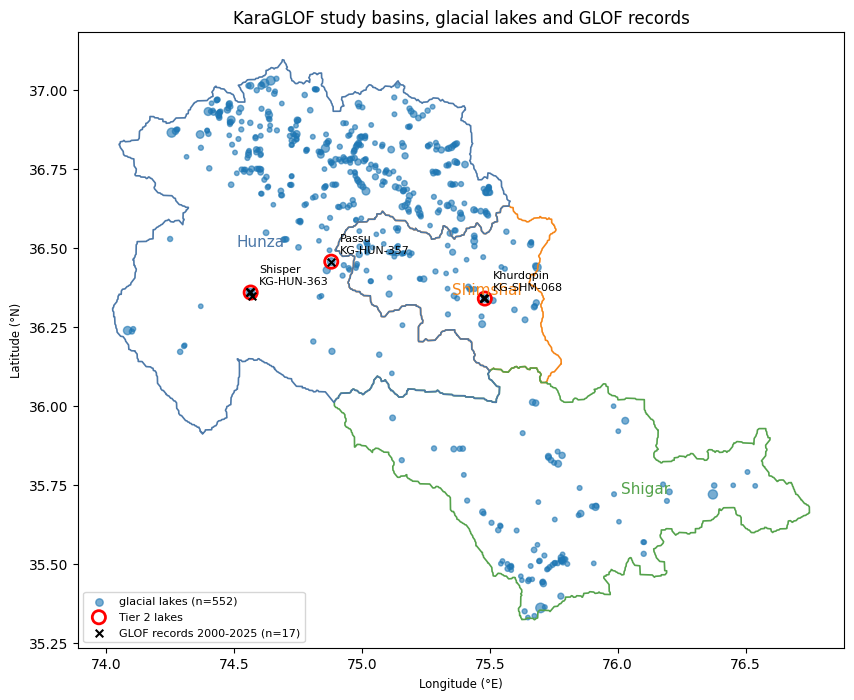

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))
colors = {"hunza": "#4c78a8", "shimshal": "#f58518", "shigar": "#54a24b"}
for _, b in basins_gdf.iterrows():
    gpd.GeoSeries([b.geometry]).boundary.plot(ax=ax, color=colors[b.basin], lw=1.2)
    ax.annotate(b.basin.title(), b.geometry.representative_point().coords[0], color=colors[b.basin], fontsize=11)
ax.scatter(lakes_gdf.lon, lakes_gdf.lat, s=4 + 60 * np.sqrt(lakes_gdf.area_ref_km2), c="#1f77b4",
           alpha=0.6, label=f"glacial lakes (n={len(lakes_gdf)})")
t2 = lakes_gdf[lakes_gdf.tier2]
ax.scatter(t2.lon, t2.lat, s=90, facecolors="none", edgecolors="red", lw=2, label="Tier 2 lakes")
for _, r in t2.iterrows():
    ax.annotate(f"{r['name']}\n{r.lake_id}", (r.lon, r.lat), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.scatter(used.lon, used.lat, marker="x", c="k", s=30, label=f"GLOF records 2000-2025 (n={len(used)})")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_aspect(1 / math.cos(math.radians(36)))
ax.set_title("KaraGLOF study basins, glacial lakes and GLOF records")
ax.legend(loc="lower left", fontsize=8)
fig.savefig(OUT / "fig_01_basins_lakes.png", dpi=200, bbox_inches="tight")
plt.show()